# ACE model evidence: calibration, conformal prediction and applicability domain

Docking cannot confirm eligibility, so the validated part of the pipeline (the ML models) has to carry the evidence. This notebook turns the raw model outputs into **per-candidate evidence that comes with measured reliability**:

1. **Calibrated probability of activity.** Raw classifier probabilities are re-mapped (Platt or isotonic, chosen by scaffold-grouped cross-validation) so that "0.7" means about 70% of similar training compounds were active. Ranking still uses the raw probability (calibration plateaus create ties).
2. **Conformal prediction sets** (class-conditional, target coverage 1 − ε): `active`, `inactive`, `uncertain (both)` or `empty`. Coverage is checked by grouped cross-validation, not assumed.
3. **Conformal prediction intervals** for pChEMBL (and IC50), widened by applicability-domain bin so far-from-training compounds get honest, wider intervals.
4. **Applicability domain (AD):** similarity to the training set, with out-of-fold performance reported per similarity bin so the thresholds are justified by data, not guessed.

All calibration uses **training-set out-of-fold predictions only** (scaffold-grouped); the external set is used only as a final check, and it is small (about 35–40 compounds), so its numbers are indicative, not decisive.

Run after notebook 3 (it reads the drugability table and the notebook 1 and 2 outputs).

In [6]:
%pip install rdkit
from pathlib import Path
import os, sys, json, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/ACE_Workflow')
except ImportError:
    ROOT = Path(os.environ.get('ACE_WORKFLOW_ROOT', Path.cwd())).resolve()
if not (ROOT / 'ace_config.py').exists():
    ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ace_config.py').exists()), ROOT)
if not (ROOT / 'ace_config.py').exists():
    raise FileNotFoundError('Could not find ace_config.py. Mount Drive or set ACE_WORKFLOW_ROOT.')
os.environ['ACE_WORKFLOW_ROOT'] = str(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import ace_config

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold

PATHS = ace_config.PATHS
RANDOM_STATE = ace_config.RANDOM_STATE
CLS_DIR, REG_DIR = PATHS['ML_CLASSIFICATION'], PATHS['ML_REGRESSION']
PROCESSED, DRUG, FIG = PATHS['DATA_PROCESSED'], PATHS['DRUGABILITY'], PATHS['VIS_FIGURES']
EVID = PATHS['ML_RESULTS'] / 'evidence'; EVID.mkdir(parents=True, exist_ok=True); Path(FIG).mkdir(parents=True, exist_ok=True)

CONFORMAL_EPSILON = 0.20                      # 80% coverage per class / for intervals
AD_EDGES = [0.0, 0.35, 0.55, 1.0001]          # max Tanimoto to the training set; check the per-bin performance table before trusting these
AD_LABELS = ['out-of-domain', 'borderline', 'in-domain']
MIN_BIN_N = 30                                # fewer calibration points than this in an AD bin -> fall back to the pooled interval
N_SPLITS = 5
ACTIVITY_PCHEMBL = 9.0 - np.log10(ace_config.IC50_CUTOFF_NM)   # 25 nM -> 7.60

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))

def max_sim(Xq, Xref, chunk=2000):
    """Max Tanimoto similarity of every row of Xq to any row of Xref (binary matrices)."""
    Xq, Xr = np.asarray(Xq, dtype=np.float32), np.asarray(Xref, dtype=np.float32); nr = Xr.sum(1)
    out = np.empty(len(Xq), dtype=np.float32)
    for i in range(0, len(Xq), chunk):
        q = Xq[i:i + chunk]; dot = q @ Xr.T; den = q.sum(1)[:, None] + nr[None, :] - dot
        out[i:i + chunk] = np.divide(dot, den, out=np.zeros_like(dot), where=den > 0).max(1)
    return out


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 40.1 MB/s  0:00:00m0:00:0100:01
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Classifier: Random Forest; 590 training compounds, 156 active (26.4%)


,brier,log_loss,ece,roc_auc
method,,,,
raw,0.1077,0.3553,0.0355,0.8906
platt,0.1099,0.3642,0.0301,0.8839
isotonic,0.1118,0.3890,0.0343,0.8694


Calibration method chosen by cross-fitted Brier score: raw
External check: n=36, 5 active (too few for a firm conclusion)


,version,brier,ece
0,raw,0.2073,0.2358
1,calibrated (raw),0.2073,0.2358


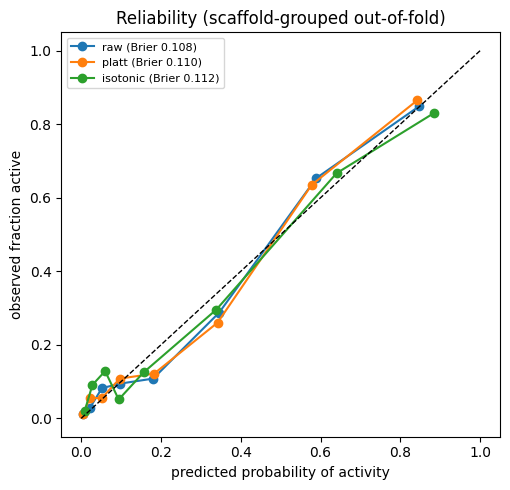

In [2]:
# 1. Classifier: out-of-fold probabilities of the selected model (from notebook 1)
cls_meta = json.loads((CLS_DIR / 'classifier_metadata.json').read_text()); CLS_MODEL = cls_meta['selected_model']
oof = pd.read_csv(CLS_DIR / 'scaffold_cv_oof_predictions.csv'); oof = oof[oof.model == CLS_MODEL].reset_index(drop=True)
train = pd.read_csv(PROCESSED / 'chembl1808_ic50_clean.csv')
assert (oof.canonical_smiles.values == train.canonical_smiles.values).all(), 'OOF rows do not align with the cleaned training table; rerun notebook 1.'
y = oof.active_ic50.to_numpy().astype(int); p_raw = oof.oof_probability_active.to_numpy(); groups = train.scaffold.astype(str).to_numpy()
print(f'Classifier: {CLS_MODEL}; {len(y)} training compounds, {int(y.sum())} active ({y.mean():.1%})')

def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
class Identity:
    def fit(self, p, y): return self
    def predict(self, p): return np.asarray(p, dtype=float)
class Platt:
    def fit(self, p, y): self.m = LogisticRegression(C=1e6, max_iter=2000).fit(logit(p).reshape(-1, 1), y); return self
    def predict(self, p): return self.m.predict_proba(logit(np.asarray(p)).reshape(-1, 1))[:, 1]
class Isotonic:
    def fit(self, p, y): self.m = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(p, y); return self
    def predict(self, p): return self.m.predict(np.asarray(p))
METHODS = {'raw': Identity, 'platt': Platt, 'isotonic': Isotonic}

def crossfit(method, p, y, groups):
    """Calibrate each scaffold-grouped fold with a calibrator fitted on the other folds (no label leakage)."""
    out = np.empty(len(p))
    for tr, te in GroupKFold(N_SPLITS).split(p, y, groups): out[te] = METHODS[method]().fit(p[tr], y[tr]).predict(p[te])
    return out
cf = {m: crossfit(m, p_raw, y, groups) for m in METHODS}
cal_table = pd.DataFrame([{'method': m, 'brier': brier_score_loss(y, v), 'log_loss': log_loss(y, np.clip(v, 1e-4, 1 - 1e-4)), 'ece': ece(y, v), 'roc_auc': roc_auc_score(y, v)} for m, v in cf.items()]).set_index('method')
display(cal_table.round(4))
CAL_METHOD = cal_table.brier.idxmin()
print('Calibration method chosen by cross-fitted Brier score:', CAL_METHOD)
final_cal = METHODS[CAL_METHOD]().fit(p_raw, y)
p_cf = cf[CAL_METHOD]           # cross-fitted calibrated OOF probabilities (used as conformal calibration data)

# external check (small set; indicative only)
ext = pd.read_csv(CLS_DIR / 'external_compound_predictions.csv'); ye = ext.active_ic50.to_numpy().astype(int); pe = ext.predicted_probability_active.to_numpy()
ext_check = pd.DataFrame([{'version': 'raw', 'brier': brier_score_loss(ye, pe), 'ece': ece(ye, pe)}, {'version': f'calibrated ({CAL_METHOD})', 'brier': brier_score_loss(ye, final_cal.predict(pe)), 'ece': ece(ye, final_cal.predict(pe))}])
print(f'External check: n={len(ye)}, {int(ye.sum())} active (too few for a firm conclusion)'); display(ext_check.round(4))

fig, ax = plt.subplots(figsize=(5.2, 5))
for m, v in cf.items():
    q = pd.qcut(v, 8, duplicates='drop'); g = pd.DataFrame({'p': v, 'y': y}).groupby(q, observed=True).mean()
    ax.plot(g.p, g.y, marker='o', label=f'{m} (Brier {cal_table.loc[m, "brier"]:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('predicted probability of activity'); ax.set_ylabel('observed fraction active'); ax.set_title('Reliability (scaffold-grouped out-of-fold)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(Path(FIG) / 'ml_reliability_curve.png', dpi=200); plt.show()


In [3]:
# 2. Class-conditional (Mondrian) split-conformal classification on the calibrated, cross-fitted OOF probabilities
def cal_scores(p, yy): return {0: np.sort(p[yy == 0]), 1: np.sort(1.0 - p[yy == 1])}      # nonconformity = 1 - P(true class)
def conformal_pvalues(p, scores):
    n0, n1 = len(scores[0]), len(scores[1])
    pv0 = (n0 - np.searchsorted(scores[0], p, side='left') + 1) / (n0 + 1)                 # class 0: nonconformity = p
    pv1 = (n1 - np.searchsorted(scores[1], 1.0 - p, side='left') + 1) / (n1 + 1)           # class 1: nonconformity = 1 - p
    return pv0, pv1
def set_labels(pv0, pv1, eps):
    i0, i1 = pv0 > eps, pv1 > eps
    return np.select([i1 & ~i0, i0 & ~i1, i0 & i1], ['active', 'inactive', 'uncertain (both)'], default='empty')

# honest coverage estimate: calibrate on the training folds, evaluate on the held-out scaffold-grouped fold
rows = []
for tr, te in GroupKFold(N_SPLITS).split(p_cf, y, groups):
    pv0, pv1 = conformal_pvalues(p_cf[te], cal_scores(p_cf[tr], y[tr])); lab = set_labels(pv0, pv1, CONFORMAL_EPSILON)
    rows.append(pd.DataFrame({'y': y[te], 'label': lab}))
cv_sets = pd.concat(rows)
covered = ((cv_sets.y == 1) & cv_sets.label.isin(['active', 'uncertain (both)'])) | ((cv_sets.y == 0) & cv_sets.label.isin(['inactive', 'uncertain (both)']))
conf_cv = pd.DataFrame({'coverage_active': [covered[cv_sets.y == 1].mean()], 'coverage_inactive': [covered[cv_sets.y == 0].mean()], 'target': [1 - CONFORMAL_EPSILON],
                        **{f'frac_{k}': [(cv_sets.label == k).mean()] for k in ['active', 'inactive', 'uncertain (both)', 'empty']}})
print('Grouped-CV conformal validation (should be close to or above the target coverage):'); display(conf_cv.round(3))
scores_final = cal_scores(p_cf, y)
pv0e, pv1e = conformal_pvalues(final_cal.predict(pe), scores_final); lab_e = set_labels(pv0e, pv1e, CONFORMAL_EPSILON)
ce = ((ye == 1) & np.isin(lab_e, ['active', 'uncertain (both)'])) | ((ye == 0) & np.isin(lab_e, ['inactive', 'uncertain (both)']))
print(f'External set (n={len(ye)}): coverage active {ce[ye == 1].mean():.2f} (n={int((ye == 1).sum())}), inactive {ce[ye == 0].mean():.2f} (n={int((ye == 0).sum())}); label counts', pd.Series(lab_e).value_counts().to_dict())


Grouped-CV conformal validation (should be close to or above the target coverage):


,coverage_active,coverage_inactive,target,frac_active,frac_inactive,frac_uncertain (both),frac_empty
0,0.801,0.797,0.8,0.341,0.627,0.002,0.031


External set (n=36): coverage active 0.80 (n=5), inactive 0.23 (n=31); label counts {'active': 19, 'empty': 10, 'inactive': 7}


In [7]:
# 3. Applicability domain: similarity of every OOF compound to the training part of ITS fold, then performance by similarity bin
X_all = ace_config.morgan_matrix(train.canonical_smiles)
exact = ~train.ic50_censored.astype(bool).to_numpy()
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X_all, y, groups))
diag_sizes = pd.read_csv(CLS_DIR / 'scaffold_cv_fold_diagnostics.csv').validation_n.tolist()
splits_match = [len(va) for _, va in splits] == diag_sizes
sim_cls_oof, sim_reg_oof = np.zeros(len(train)), np.zeros(len(train))
if splits_match:
    print('Recomputed folds match notebook 1 (validation fold sizes identical).')
    for tr, va in splits:
        sim_cls_oof[va] = max_sim(X_all[va], X_all[tr]); sim_reg_oof[va] = max_sim(X_all[va], X_all[tr[exact[tr]]])
else:
    print('WARNING: recomputed folds differ from notebook 1; using leave-scaffold-out similarity instead (approximate).')
    for g in np.unique(groups):
        m = groups == g; ref = ~m
        sim_cls_oof[m] = max_sim(X_all[m], X_all[ref]); sim_reg_oof[m] = max_sim(X_all[m], X_all[ref & exact])
ad_bin_oof = pd.cut(pd.Series(sim_cls_oof), AD_EDGES, labels=AD_LABELS, right=False)
ad_rows = []
for lab in AD_LABELS:
    m = (ad_bin_oof == lab).to_numpy()
    if not m.any(): ad_rows.append({'ad_level': lab, 'n': 0, 'n_active': 0, 'brier_calibrated': np.nan, 'roc_auc': np.nan}); continue
    yy, pp = y[m], p_cf[m]
    ad_rows.append({'ad_level': lab, 'n': int(m.sum()), 'n_active': int(yy.sum()), 'brier_calibrated': brier_score_loss(yy, pp),
                    'roc_auc': roc_auc_score(yy, pp) if yy.sum() >= 5 and (yy == 0).sum() >= 5 else np.nan})
ad_cls = pd.DataFrame(ad_rows).set_index('ad_level')
print('Classifier out-of-fold performance by applicability-domain bin:'); display(ad_cls.round(3))


Recomputed folds match notebook 1 (validation fold sizes identical).
Classifier out-of-fold performance by applicability-domain bin:


,n,n_active,brier_calibrated,roc_auc
ad_level,,,,
out-of-domain,33,4,0.109,NaN
borderline,80,7,0.074,0.774
in-domain,477,145,0.113,0.898


Regressor tanimoto_svr: grouped-CV conformal coverage 0.780 (target 0.80); mean width 2.32 pChEMBL units


,n,coverage,mean_interval_width,rmse
bin,,,,
out-of-domain,29,0.414,2.545,2.173
borderline,65,0.831,3.045,1.359
in-domain,452,0.796,2.199,0.934


Interval half-widths used (pChEMBL units): {'out-of-domain': (1.26, 'pooled'), 'borderline': (1.48, 'bin'), 'in-domain': (1.1, 'bin')}
External set: n=36, interval coverage 0.78 (small n; indicative only); AD bins {'in-domain': 31, 'borderline': 4, 'out-of-domain': 1}


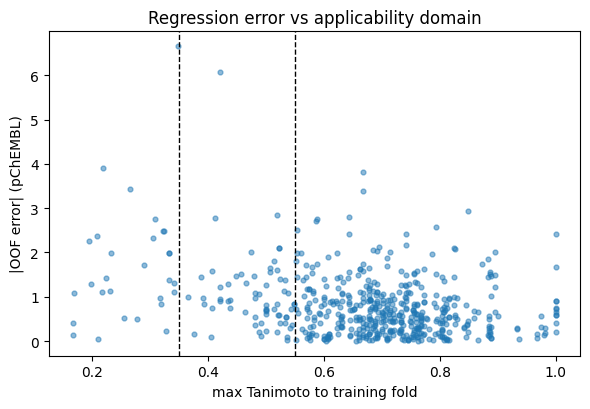

In [8]:
# 4. Regressor: conformal intervals, widened per applicability-domain bin
reg_meta = json.loads((REG_DIR / 'regressor_metadata.json').read_text()); REG_MODEL = reg_meta['selected_model']
roof = pd.read_csv(REG_DIR / 'regression_cv_oof_predictions.csv')
tr_exact = train[exact].reset_index(drop=True)
assert (roof.canonical_smiles.values == tr_exact.canonical_smiles.values).all(), 'Regression OOF rows do not align; rerun notebook 2.'
yr, yhat = roof.pchembl.to_numpy(), roof[f'oof_{REG_MODEL}'].to_numpy(); res = np.abs(yr - yhat)
sim_r = sim_reg_oof[exact]; bin_r = pd.cut(pd.Series(sim_r), AD_EDGES, labels=AD_LABELS, right=False).astype(str).to_numpy(); grp_r = tr_exact.scaffold.astype(str).to_numpy()

def q_level(r, eps):
    n = len(r); k = int(np.ceil((n + 1) * (1 - eps))); return float(np.sort(r)[min(k, n) - 1])
def bin_q(r, b, eps):
    qg = q_level(r, eps); out = {}
    for lab in AD_LABELS:
        m = b == lab; out[lab] = (q_level(r[m], eps), 'bin') if m.sum() >= MIN_BIN_N else (qg, 'pooled')
    return out, qg

rows = []
for tr, te in GroupKFold(N_SPLITS).split(yr, yr, grp_r):
    qd, _ = bin_q(res[tr], bin_r[tr], CONFORMAL_EPSILON)
    w = np.array([qd[b][0] for b in bin_r[te]]); rows.append(pd.DataFrame({'bin': bin_r[te], 'covered': res[te] <= w, 'width': 2 * w, 'abs_err': res[te]}))
reg_cv = pd.concat(rows)
reg_ad = reg_cv.groupby('bin').agg(n=('covered', 'size'), coverage=('covered', 'mean'), mean_interval_width=('width', 'mean'), rmse=('abs_err', lambda x: float(np.sqrt(np.mean(x ** 2))))).reindex(AD_LABELS)
print(f'Regressor {REG_MODEL}: grouped-CV conformal coverage {reg_cv.covered.mean():.3f} (target {1 - CONFORMAL_EPSILON:.2f}); mean width {reg_cv.width.mean():.2f} pChEMBL units'); display(reg_ad.round(3))
Q_BIN, Q_GLOBAL = bin_q(res, bin_r, CONFORMAL_EPSILON)
print('Interval half-widths used (pChEMBL units):', {k: (round(v[0], 2), v[1]) for k, v in Q_BIN.items()})

# external check (exact-value external compounds)
rext = pd.read_csv(REG_DIR / 'regression_external_predictions.csv'); Xext = ace_config.morgan_matrix(rext.canonical_smiles)
sim_e = max_sim(Xext, X_all[exact]); bin_e = pd.cut(pd.Series(sim_e), AD_EDGES, labels=AD_LABELS, right=False).astype(str).to_numpy()
cov_e = np.array([abs(a - b) <= Q_BIN[bb][0] for a, b, bb in zip(rext.pchembl, rext.predicted_pchembl, bin_e)])
print(f'External set: n={len(rext)}, interval coverage {cov_e.mean():.2f} (small n; indicative only); AD bins {pd.Series(bin_e).value_counts().to_dict()}')

fig, ax = plt.subplots(figsize=(6, 4.2)); ax.scatter(sim_r, res, s=12, alpha=.5)
for e in AD_EDGES[1:-1]: ax.axvline(e, color='k', ls='--', lw=1)
ax.set_xlabel('max Tanimoto to training fold'); ax.set_ylabel('|OOF error| (pChEMBL)'); ax.set_title('Regression error vs applicability domain'); fig.tight_layout(); fig.savefig(Path(FIG) / 'ml_error_vs_similarity.png', dpi=200); plt.show()


In [9]:
# 5. Apply to the screened candidates and save
cand = pd.read_csv(DRUG / 'ace_drugability_all_candidates.csv')
need = {'canonical_smiles', 'source', 'ace_active_probability', 'predicted_pchembl', 'max_train_tanimoto_cls', 'max_train_tanimoto_reg'}
missing = need - set(cand.columns)
if missing: raise KeyError(f'Drugability table lacks {sorted(missing)}; rerun notebooks 1-3 with the current versions.')
cand['p_active_raw'] = cand.ace_active_probability
cand['p_active_cal'] = final_cal.predict(cand.p_active_raw.to_numpy())
pv0, pv1 = conformal_pvalues(cand.p_active_cal.to_numpy(), scores_final)
cand['conformal_p_inactive'], cand['conformal_p_active'] = pv0, pv1
cand['conformal_set'] = set_labels(pv0, pv1, CONFORMAL_EPSILON)
cand['ad_level_cls'] = pd.cut(cand.max_train_tanimoto_cls, AD_EDGES, labels=AD_LABELS, right=False).astype(str)
cand['ad_level_reg'] = pd.cut(cand.max_train_tanimoto_reg, AD_EDGES, labels=AD_LABELS, right=False).astype(str)
rank = {l: i for i, l in enumerate(AD_LABELS)}
cand['ad_level'] = [a if rank[a] <= rank[b] else b for a, b in zip(cand.ad_level_cls, cand.ad_level_reg)]   # the stricter of the two
half = cand.ad_level_reg.map(lambda b: Q_BIN[b][0]); cand['interval_basis'] = cand.ad_level_reg.map(lambda b: Q_BIN[b][1])
cand['pchembl_pred'] = cand.predicted_pchembl; cand['pchembl_lo'] = cand.pchembl_pred - half; cand['pchembl_hi'] = cand.pchembl_pred + half
cand['ic50_pred_nM'] = 10 ** (9 - cand.pchembl_pred); cand['ic50_lo_nM'] = 10 ** (9 - cand.pchembl_hi); cand['ic50_hi_nM'] = 10 ** (9 - cand.pchembl_lo)
cand['reg_interval_clears_cutoff'] = cand.pchembl_lo >= ACTIVITY_PCHEMBL         # whole interval at or below the IC50 cutoff
cand['reg_interval_overlaps_cutoff'] = (cand.pchembl_hi >= ACTIVITY_PCHEMBL) & ~cand.reg_interval_clears_cutoff
keep = ['source', 'source_id', 'canonical_smiles', 'p_active_raw', 'p_active_cal', 'conformal_p_active', 'conformal_p_inactive', 'conformal_set', 'pchembl_pred', 'pchembl_lo', 'pchembl_hi',
        'ic50_pred_nM', 'ic50_lo_nM', 'ic50_hi_nM', 'reg_interval_clears_cutoff', 'reg_interval_overlaps_cutoff', 'interval_basis',
        'max_train_tanimoto_cls', 'max_train_tanimoto_reg', 'ad_level_cls', 'ad_level_reg', 'ad_level']
keep = [c for c in keep if c in cand.columns]
cand[keep].to_csv(EVID / 'ml_evidence_candidates.csv', index=False)
summary = {'classifier_model': CLS_MODEL, 'calibration_method': CAL_METHOD, 'calibration_table': cal_table.round(4).to_dict(), 'conformal_epsilon': CONFORMAL_EPSILON,
           'conformal_grouped_cv': conf_cv.round(4).to_dict('records')[0], 'regressor_model': REG_MODEL, 'regression_grouped_cv_coverage': float(reg_cv.covered.mean()),
           'interval_half_widths_pchembl': {k: [round(v[0], 3), v[1]] for k, v in Q_BIN.items()}, 'ad_edges': AD_EDGES, 'ad_labels': AD_LABELS,
           'folds_match_notebook1': bool(splits_match), 'external_n_classifier': int(len(ye)), 'external_n_regressor': int(len(rext)), 'activity_pchembl_cutoff': float(ACTIVITY_PCHEMBL)}
(EVID / 'ml_evidence_summary.json').write_text(json.dumps(summary, indent=2, default=float))
ad_cls.to_csv(EVID / 'ml_ad_performance_classifier.csv'); reg_ad.to_csv(EVID / 'ml_ad_performance_regressor.csv')
print(f'Saved {len(cand):,} candidates to {EVID / "ml_evidence_candidates.csv"}')
print('Conformal sets:', cand.conformal_set.value_counts().to_dict()); print('AD levels:', cand.ad_level.value_counts().to_dict())
display(cand[keep].sort_values('p_active_raw', ascending=False).head(15).round(3))


Saved 159,658 candidates to /content/drive/MyDrive/ACE_Workflow/ml_model/results/evidence/ml_evidence_candidates.csv
Conformal sets: {'inactive': 157793, 'empty': 1193, 'active': 672}
AD levels: {'out-of-domain': 151085, 'borderline': 7567, 'in-domain': 1006}


,source,source_id,canonical_smiles,p_active_raw,p_active_cal,conformal_p_active,conformal_p_inactive,conformal_set,pchembl_pred,pchembl_lo,...,ic50_lo_nM,ic50_hi_nM,reg_interval_clears_cutoff,reg_interval_overlaps_cutoff,interval_basis,max_train_tanimoto_cls,max_train_tanimoto_reg,ad_level_cls,ad_level_reg,ad_level
0,FDA_DRUGBANK,Enalaprilat,CC(NC(CCc1ccccc1)C(=O)O)C(=O)N1CCCC1C(=O)O,0.943,0.943,0.981,0.005,active,8.420,7.319,...,0.301,47.974,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
1,FDA_DRUGBANK,Lisinopril,NCCCCC(NC(CCc1ccccc1)C(=O)O)C(=O)N1CCCC1C(=O)O,0.940,0.940,0.968,0.005,active,8.600,7.499,...,0.199,31.722,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
5,NPASS,NPC483990,CC(CS)C(=O)N1CCCC1C(=O)O,0.867,0.867,0.783,0.009,active,7.490,6.389,...,2.566,408.702,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
4,FDA_DRUGBANK,Captopril,CC(CS)C(=O)N1CCCC1C(=O)O,0.867,0.867,0.783,0.009,active,7.490,6.389,...,2.566,408.702,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
6,PLANTS_CMAUP,FAKRSMQSSFJEIM-RQJHMYQMSA-N,CC(CS)C(=O)N1CCCC1C(=O)O,0.867,0.867,0.783,0.009,active,7.490,6.389,...,2.566,408.702,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
3,PLANTS_CMAUP,IFGCUJZIWBUILZ-UHFFFAOYSA-N,CC(C)CC(NP(=O)(O)OC1OC(C)C(O)C(O)C1O)C(=O)NC(C...,0.696,0.696,0.567,0.030,active,8.100,6.999,...,0.630,100.288,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
2,NPASS,NPC313640,CC(C)CC(NP(=O)(O)OC1OC(C)C(O)C(O)C1O)C(=O)NC(C...,0.696,0.696,0.567,0.030,active,8.100,6.999,...,0.630,100.288,False,True,bin,1.000,1.000,in-domain,in-domain,in-domain
7,NPASS,NPC249334,CCC(C)C(=O)NC1CCC(=O)N(CCc2ccccc2)C1=O,0.578,0.578,0.414,0.053,active,6.644,5.165,...,7.541,6840.001,False,True,bin,0.508,0.508,borderline,borderline,borderline
8,FDA_DRUGBANK,Losartan,CCCCc1nc(Cl)c(CO)n1Cc1ccc(-c2ccccc2-c2nn[nH]n2...,0.502,0.502,0.350,0.080,active,6.687,5.586,...,16.303,2597.125,False,True,bin,0.710,0.710,in-domain,in-domain,in-domain
13,NPASS,NPC27833,CC(=O)NC1CCC(=O)N(CC(=O)c2ccccc2)C1=O,0.480,0.480,0.318,0.085,active,5.956,4.477,...,36.768,33349.905,False,False,bin,0.483,0.483,borderline,borderline,borderline


### How to read the evidence columns

- `p_active_cal`: calibrated probability of IC50 <= the activity cutoff, learned from scaffold-grouped out-of-fold predictions. Use `p_active_raw` for ranking.
- `conformal_set`: `active` / `inactive` are confident calls at the chosen coverage; `uncertain (both)` means the model cannot separate the classes for that compound; `empty` usually signals an atypical compound.
- `pchembl_lo`..`pchembl_hi` (and `ic50_lo_nM`..`ic50_hi_nM`): conformal interval. `interval_basis = pooled` means the AD bin had too few calibration points and the pooled width was used.
- `ad_level`: `in-domain` / `borderline` / `out-of-domain` from similarity to the training set (the stricter of classifier and regressor). The per-bin performance tables above show how much the models degrade away from the training chemistry; out-of-domain predictions should be treated as exploratory.
- All of this describes the **models' reliability**, not proof of activity; experimental inhibition assays are still required.